# Prova - Laboratório de Extração e Análise de Dados

Prof. Matheus C. Pestana

#### Fundação Getúlio Vargas - Escola de Comunicação, Mídia e Informação (FGV ECMI)

## INSTRUÇÕES - LEIA ATENTAMENTE

- Tome cuidado: resolva exatamente o que a questão pede.
- Organize seu código e faça indicações e comentários, se preciso for. Você pode utilizar a célula de texto do próprio Colab, que funciona com a linguagem Markdown)
- Evite alterar as células que contém "código auxiliar".
- __Para enviar a prova, clique em Arquivo/File/Ficheiro no menu superior do Colab, vá em "Fazer Download" e então em "Fazer download do .ipynb". Certifique-se de que todas as saídas estão presentes. Envie esse arquivo na atividade correspondente no eClass.__
- Entre a questão 2 e 6, escolha **apenas uma**. Antes de entregar, delete a célula da questão que você **não escolheu**.
- Caso queira consultar os códigos dados em sala, o nosso repositório no Github está localizado [aqui](https://github.com/mateuspestana/LabExtracaoAnalise_ECMI).

In [1]:
# Baixando e importando bibliotecas
!pip install yfinance

import time
import requests
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
from tqdm import tqdm
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, NMF, LatentDirichletAllocation
from sklearn.cluster import KMeans
from collections import Counter
from wordcloud import WordCloud
import warnings
import yfinance as yf
import math
warnings.filterwarnings('ignore')

1) Realize a análise do seguinte dataset, iniciado na célula abaixo. São as postagens da conta **@latinialonso** do Tiktok. Extraia as seguintes informações e as digite no campo abaixo da célula de código. (Total: 1,0)

- Média de likes (0,1)
- Média de comentários (0,1)
- Média de shares (0,1)
- Média de duração dos vídeos (0,1)
- A música mais utilizada nos vídeos (variável *music*, desconsiderando 'som original') (0,2)
- Um gráfico que indique quantos vídeos por mês foram postados (0,2)
- Quais as 5 hashtags mais utilizadas (0,2)

*Lembre-se: internamente, as hashtags que queremos do TikTok são chamadas de __challenges__*


In [53]:
# CÓDIGO AUXILIAR
latini = pd.read_csv('https://raw.githubusercontent.com/mateuspestana/LabExtracaoAnalise_ECMI/main/bases/latinialonso.csv')
latini['timestamp'] = pd.to_datetime(latini['timestamp'])
latini.set_index('timestamp', inplace=True)

Média de Likes: 6041.314285714286
Média de Comentários: 84.15238095238095
Média de Compartilhamentos: 154.95238095238096
Música mais utilizada: 6827446890867460097


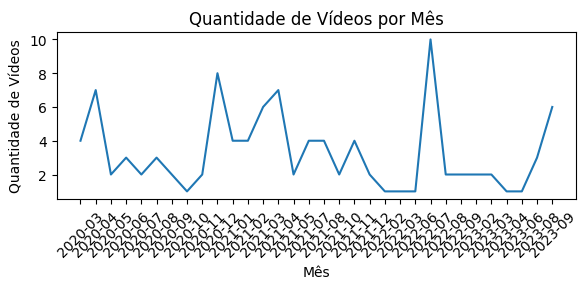

[('ad', 105), ('magic', 105), ('magica', 105), ('fyp', 105), ('fy', 105)]

In [117]:
# RESPOSTAS

latini.describe()
#Média de likes
media_likes = latini['likes'].mean()

print("Média de Likes:", media_likes)

#Média de comentários
media_comentários = latini['comments'].mean()

print("Média de Comentários:", media_comentários)

#Média de shares
media_shares = latini['shares'].mean()

print("Média de Compartilhamentos:", media_shares)

#A música mais utilizada nos vídeos
music_counts = latini['music_id'].value_counts()

musica_mais_utilizada = music_counts.idxmax()

print("Música mais utilizada:", musica_mais_utilizada)

#Gráfico indicando quantos vídeos por mês foram postados
latini['data'] = pd.to_datetime(latini['unix_timestamp'], unit='s')

latini['month'] = latini['data'].dt.strftime('%Y-%m')

videos_por_mes = latini['month'].value_counts().sort_index()

plt.figure(figsize=(6, 3))
sns.lineplot(data=videos_por_mes, x=videos_por_mes.index, y=videos_por_mes.values)
plt.xlabel('Mês')
plt.ylabel('Quantidade de Vídeos')
plt.title('Quantidade de Vídeos por Mês')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

#Quais as 5 hashtags mais utilizadas
latini_challenges = latini['challenges'].str.split(',')

all_challenges = []

for challenges_list in latini_challenges:
    all_challenges.extend(challenges_list)

word_counter = Counter(all_challenges)
top_words = word_counter.most_common(5)

top_words





Análise:

2) Com a mesma base da questão 1 (Total: 2,0 - **ESCOLHA ENTRE ESSA E A 6**)

- utilize as hashtags de *challenges* para construir uma nuvem de palavras com elas. Utilize no máximo 150 palavras na nuvem de palavras. (0,6)

- Faça uma modelagem de tópicos (utilizando ou LDA ou NMF) com **todas** as hashtags. (0,8)

- Interprete os resultados em texto corrido, falando sobre cada um dos tópicos encontrados (0,6)

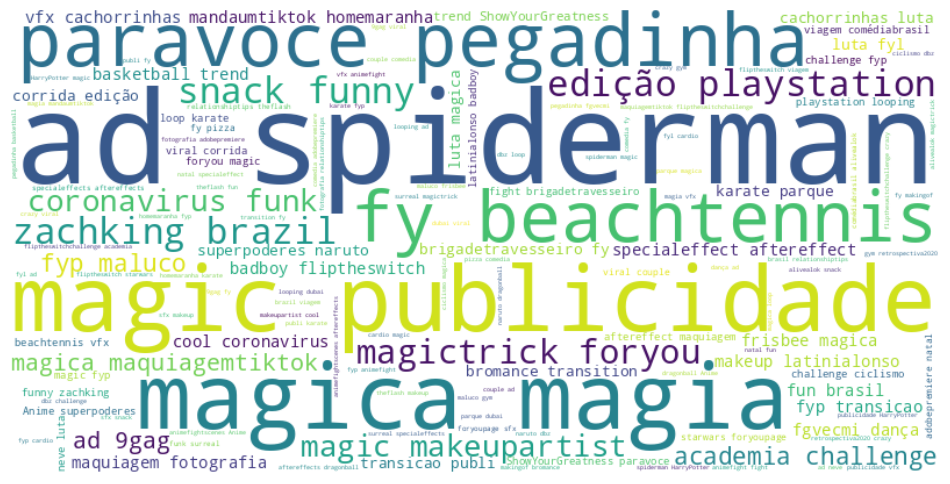

Top 15 challenges por tópico: #0
['dança', 'magia', 'mandaumtiktok', 'publi', 'aftereffects', 'viral', 'challenge', 'fyp', 'ad', 'fy', 'magic', 'magica', 'karate', 'luta', 'vfx']


Top 15 challenges por tópico: #1
['edição', 'fight', 'corrida', 'ciclismo', 'fyl', 'animefightscenes', 'loop', 'cardio', 'dbz', 'naruto', 'beachtennis', 'neve', 'parque', 'looping', 'brigadetravesseiro']


Top 15 challenges por tópico: #2
['basketball', 'harrypotter', 'bromance', 'cachorrinhas', 'publicidade', 'publi', 'paravoce', 'dança', 'fgvecmi', 'mandaumtiktok', 'makingof', 'magia', 'homemaranha', 'showyourgreatness', 'pegadinha']


Top 15 challenges por tópico: #3
['dança', 'magia', 'mandaumtiktok', 'publi', 'aftereffects', 'viral', 'challenge', 'fyp', 'ad', 'fy', 'magic', 'magica', 'luta', 'karate', 'vfx']




In [134]:
# RESPOSTAS

#Nuvem de palavras com cap em 150:
latini_challenges = latini['challenges'].str.split(', ')

wordcloud = WordCloud(width=800, height=400, max_font_size=150, max_words=150, background_color='white').generate(' '.join(latini_challenges.sum()))
plt.figure(figsize=(12, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

#Modelagem de tópicos (utilizando ou LDA ou NMF) com todas as hashtags.
latini_challenges = latini['challenges'].str.split(',')

tfidf = TfidfVectorizer()
LDA = LatentDirichletAllocation(n_components = 4)
challenges = tfidf.fit_transform(latini_challenges.apply(lambda x: ' '.join(x)))
challenges_nmf = LDA.fit_transform(challenges)

for index, topic in enumerate(LDA.components_):
    print(f'Top 15 challenges por tópico: #{index}')
    print([tfidf.get_feature_names_out()[i] for i in topic.argsort()[-15:]])
    print('\n')

Análise: Os tópicos convergem em muitas partes, mas é possível observar:
No tópico #0, existe associação entre produtos da cultura pop, como "spiderman", "harrypotter" e "homemaranha"

No tópico #1, Existe a associação entre dança, "challenges" e efeitos especiais.

No tópico #2, Encontram se resultados semelhantes ao #1

No tópico #3, Bastante menção a esportes e animes.


3) Você trabalha no marketing de uma marca de roupas. Você foi responsável por coletar dados de perfil dos clientes, e agora precisa segmentá-los para entendê-los e posicionar melhor a sua marca. A partir da base "clientes.csv", termine o código iniciado abaixo, e interprete os resultados depois. (Total: 1,5)

**Codificação**

Sexo: 0 = Masculino, 1 = Feminino

Estado Civil: 0 = Solteiro, 1 = Não-solteiro (casado, divorciado, viúvo, etc)

Escolaridade: 0 = Ensino Fundamental, 1 = Ensino Médio, 2 = Graduação, 3 = Pós-Graduação

Ocupação: 0 = Desempregado, 1 = Trabalhador não-especializado, 2 = Trabalhador Especializado

TamanhoCidade: 0 = Interior, 1 = Cidade Média, 2 = Cidade grande/capital

**Requisitos**

- Faça a segmentação usando o K-Means. Não esqueça de normalizar os dados antes (**StandardScaler**). Se quiser, utilize o PCA reduzindo para 2 ou 3 dimensões. (0,6).

- Plote os clusters (0,6)

- Apresente o perfil de cada cluster, por exemplo:
  *O cluster 1 é majoritariamente formado por homens, cuja média de idade é 19, renda média R$1100, moram mais em cidades grandes, são solteiros e não fizeram graduação) (0,3)


In [80]:
# CÓDIGO AUXILIAR
clientes = pd.read_csv('https://github.com/mateuspestana/LabExtracaoAnalise_ECMI/raw/main/bases/clientes.csv').set_index('ID')
clientes

stdscaler = StandardScaler()
pca = PCA(n_components=2)
kmeans = KMeans(n_clusters=4)

In [ ]:
# RESPOSTA
segmentação = clientes[['Sexo', 'Estado Civil', 'Escolaridade', 'Ocupação' ]]

pca = PCA(n_components=4)
standard_scaler = StandardScaler()
kmeans = KMeans(n_clusters=3, n_init=10, max_iter=300)

segmentacao_scaled = standard_scaler.fit_transform(segmentação)
segmentacao_reduzida = pca.fit_transform(segmentacao_scaled)

segmentacao_kmeans = kmeans.fit(segmentacao_reduzida)

segmentação['cluster'] = segmentacao_kmeans.labels_

plt.figure(figsize=(10, 10))
plt.scatter(segmentacao_reduzida[:, 0], segmentacao_reduzida[:, 1], c=segmentacao_kmeans.labels_, cmap='plasma')
plt.show()

for cluster_id in range(4):
    cluster_data = clientes[clientes['cluster'] == cluster_id]
    print(f'Perfil do Cluster {cluster_id + 1}:')
    print(f" - Sexo: {'Feminino' if cluster_data['Sexo'].mean() > 0.5 else 'Masculino'}")
    print(f" - Estado Civil: {'Não-solteiro' if cluster_data['Estado Civil'].mean() > 0.5 else 'Solteiro'}")
    print(f" - Idade Média: {cluster_data['Idade'].mean():.2f} anos")
    print(f" - Escolaridade: {'Pós-Graduação' if cluster_data['Escolaridade'].mean() == 3 else 'Graduação' if cluster_data['Escolaridade'].mean() == 2 else 'Ensino Médio' if cluster_data['Escolaridade'].mean() == 1 else 'Ensino Fundamental'}")
    print(f" - Renda Média: R${cluster_data['Renda'].mean():.2f}")
    print(f" - Ocupação: {'Trabalhador Especializado' if cluster_data['Ocupação'].mean() > 1.9 else 'Trabalhador não-especializado' if cluster_data['Ocupação'].mean == 1 else 'Desempregado'}")
    print(f" - Tamanho da Cidade: {'Cidade grande/capital' if cluster_data['TamanhoCidade'].mean() == 2 else 'Cidade Média' if cluster_data['TamanhoCidade'].mean() == 1 else 'Interior'}")
    print()

Análise:

Perfil do Cluster 1:
- Sexo: Masculino
 - Estado Civil: Solteiro
 - Idade Média: 35.58 anos
 - Escolaridade: Ensino Fundamental
 - Renda Média: R$1631.00
 - Ocupação: Desempregado
 - Tamanho da Cidade: Interior

Perfil do Cluster 2:
 - Sexo: Feminino
 - Estado Civil: Não-solteiro
 - Idade Média: 28.96 anos
 - Escolaridade: Ensino Fundamental
 - Renda Média: R$1762.65
 - Ocupação: Desempregado
 - Tamanho da Cidade: Interior

Perfil do Cluster 3:
 - Sexo: Feminino
 - Estado Civil: Não-solteiro
 - Idade Média: 55.70 anos
 - Escolaridade: Ensino Fundamental
 - Renda Média: R$2638.97
 - Ocupação: Desempregado
 - Tamanho da Cidade: Interior

Perfil do Cluster 4:
 - Sexo: Masculino
 - Estado Civil: Solteiro
 - Idade Média: 35.64 anos
 - Escolaridade: Ensino Fundamental
 - Renda Média: R$2353.64
 - Ocupação: Desempregado
 - Tamanho da Cidade: Interior

4) Com o objetivo de fazer um estudo sobre o carnaval carioca, você precisará raspar, da página https://pt.wikipedia.org/wiki/Lista_de_campe%C3%A3s_do_carnaval_do_Rio_de_Janeiro , a tabela que tem as escolas campeãs do carnaval, entre 1932 e 2023, da seção "Campeãs por ano" (Total: 1,0)

- Exiba a tabela (0,7)
- Remova as linhas que não correspondem a uma escola de samba, mas sim cabeçalhos de sub-tabelas (0,3)



In [136]:
# RESPOSTA
session = requests.Session()
session.headers.update({'User-Agent': 'Mozilla/5.0'})
url = f'https://pt.wikipedia.org/wiki/Lista_de_campe%C3%A3s_do_carnaval_do_Rio_de_Janeiro'

response = requests.get(url)

if response.status_code == 200:
    soup = BeautifulSoup(response.text, 'html.parser')


    campeas = soup.find_all('a', class_='title')

    lista_campeas = []

    for campea in campeas:
        nome_escola = campea.find('a', class_='title').text
        ano_campeonato = campea.find('span', class_='ano-campeonato').text
        lista_campeas.append({'Escola': nome_escola, 'Ano': ano_campeonato})


    for campea in lista_campeas:
        print(f"Escola: {campea['Escola']}, Ano: {campea['Ano']}")
else:
    print(f'Falha ao acessar a URL. Status Code: {response.status_code}')


5) Dado um conjunto de palavras em uma lista, escreva uma função que retorne a palavra mais longa da lista. Se houver mais de uma palavra com o mesmo tamanho máximo, retorne a que aparece primeiro na lista. (Total: 1,0)

**Requisitos:**

- A função deve se chamar `palavra_mais_longa`.
- Deve aceitar uma lista de strings como argumento.
- Utilize estruturas de repetição (for) e condicionais (if, else).

```
palavra_mais_longa(["gato", "cachorro", "tartaruga"])
# Deve retornar: "tartaruga", pois é a palavra mais longa da lista.

palavra_mais_longa(["carro", "avião", "trem"])
# Deve retornar: "carro", pois é a primeira palavra com o maior tamanho na lista.

palavra_mais_longa([])
# Deve retornar: None, pois a lista está vazia.
```



In [115]:
# RESPOSTA

def palavra_mais_longa(lista):
  # ESCREVA A FUNÇÃO AQUI

   if not lista:
       return None

   palavra_mais_longa = lista[0]

   for palavra in lista:
      if len(palavra) > len(palavra_mais_longa):
            palavra_mais_longa = palavra
      elif len(palavra) == len(palavra_mais_longa):
           continue

   return palavra_mais_longa

print(palavra_mais_longa(["gato", "cachorro", "tartaruga"]))
print(palavra_mais_longa(["carro", "avião", "trem"]))
print(palavra_mais_longa([]))

tartaruga
carro
None


In [137]:
# Para testar:
print(palavra_mais_longa(["gato", "cachorro", "tartaruga"])) # Precisa retornar "tartaruga" - 0,33
print(palavra_mais_longa(["carro", "avião", "trem"])) # Precisa retornar "carro" - 0,33
print(palavra_mais_longa([])) # Precisa retornar None - 0,33

tartaruga
carro
None
